# Chương 3: Phân Tích Dữ Liệu Khám Phá (EDA) & Tiền Xử Lý Chống Rò Rỉ
## Sequence-to-Sequence Weather Forecasting — Jena Climate (Topic 5)

Notebook trình bày **10 biểu đồ cốt lõi (không trùng ý)** đi theo đúng **Quy trình 4 pha chống rò rỉ (Strict Anti-Leakage)** cho bài toán dự báo **168 giờ quá khứ $\rightarrow$ 72 giờ tương lai**:
1. **Lọc cảm biến lỗi** (`-9999.0 -> NaN`) và gom mẫu `1h`.
2. **Pha 1 (Split First):** Chia tuần tự theo thời gian **70% Train — 15% Val — 15% Test**.
3. **Pha 2 (EDA on Train Only):** 6 biểu đồ phân tích chuyên sâu chỉ trên 70% Train.
4. **Pha 3 & Pha 4:** Chuẩn hóa `StandardScaler` chỉ `fit` trên Train + Cửa sổ trượt độc lập + Kiểm định `verify_zero_leakage()`.

In [1]:
%matplotlib inline
import os, sys, yaml
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.rcParams["figure.dpi"] = 110
sns.set_style("whitegrid")

from src.data_module import JenaDataModule
from src.eda import (
    plot_wind_anomalies, plot_data_split_timeline, plot_temperature_trend,
    plot_temperature_distribution, plot_diurnal_cycle, plot_correlation_heatmap,
    plot_scatter_relationships, plot_autocorrelation,
    plot_scaling_comparison, plot_sliding_window_example, summarize_eda_insights,
)
print("Sẵn sàng chạy EDA!")

Sẵn sàng chạy EDA!


---
## Phần 1: Nạp Dữ Liệu Gốc & Lọc Cảm Biến Lỗi (`-9999.0`)

Dữ liệu gốc: 420,551 dòng x 15 cột


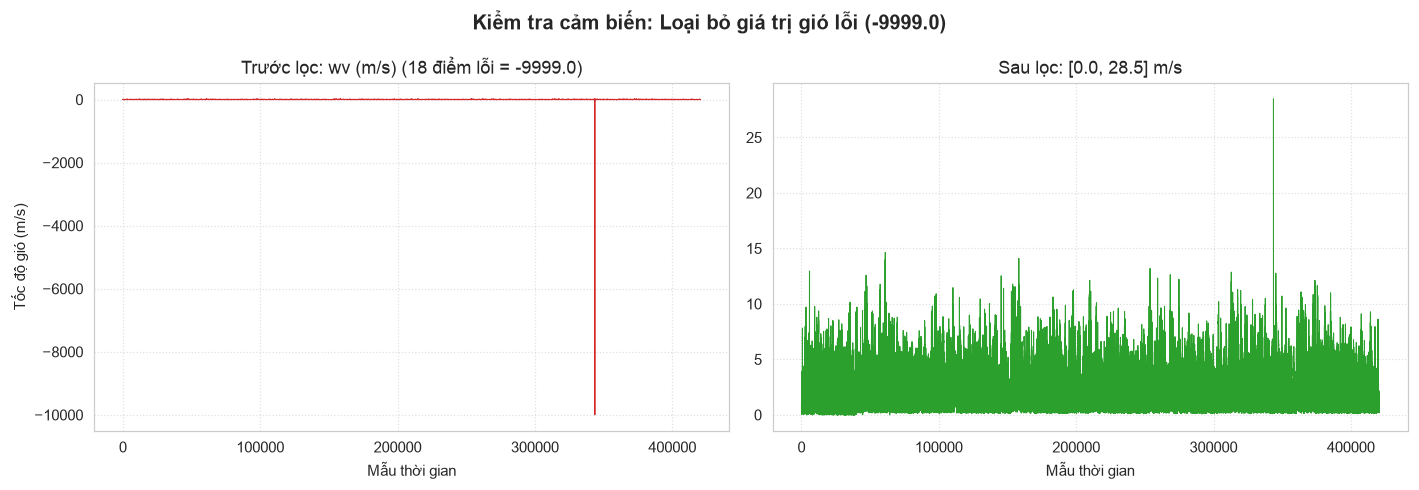

In [2]:
with open("../configs/config.yaml", "r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)["data"]

raw_csv_path = os.path.join("..", cfg["raw_csv_path"])
dm = JenaDataModule(
    raw_csv_path=raw_csv_path,
    seq_len=cfg["seq_len"],
    pred_len=cfg["pred_len"],
    target_col=cfg["target_col"],
    train_ratio=cfg["train_ratio"],
    val_ratio=cfg["val_ratio"],
    test_ratio=cfg["test_ratio"],
    resample_rule=cfg["resample_rule"],
    invalid_wind_val=cfg.get("invalid_wind_val", -9999.0),
)

raw_df = pd.read_csv(raw_csv_path)
print(f"Dữ liệu gốc: {raw_df.shape[0]:,} dòng x {raw_df.shape[1]} cột")
plot_wind_anomalies(raw_df, invalid_val=dm.invalid_wind_val)

**Biểu đồ 1 — Lọc lỗi cảm biến gió (`Line Chart`):**
- **Là gì & Tại sao chọn Line:** So sánh trực tiếp chuỗi tốc độ gió trước và sau khi thay `-9999.0 -> NaN` để thấy ngay các điểm nhiễu cực đoan kéo dẹt toàn bộ trục tung.
- **Ý nghĩa cho mô hình:** Nếu không lọc trước, `-9999.0` sẽ làm méo hoàn toàn Mean/Std của `StandardScaler` và gây nổ gradient khi huấn luyện.

---
## Phần 2: Pha 1 — Resample `1h` & Chia Tuần Tự Theo Thời Gian (Split First)

Tổng sau Resample 1h: 70,129 giờ
  - Train (70%): 49,090h (2009-01-01 00:00:00 -> 2014-08-08 09:00:00)
  - Val   (15%): 10,519h (2014-08-08 10:00:00 -> 2015-10-20 16:00:00)
  - Test  (15%): 10,520h (2015-10-20 17:00:00 -> 2017-01-01 00:00:00)


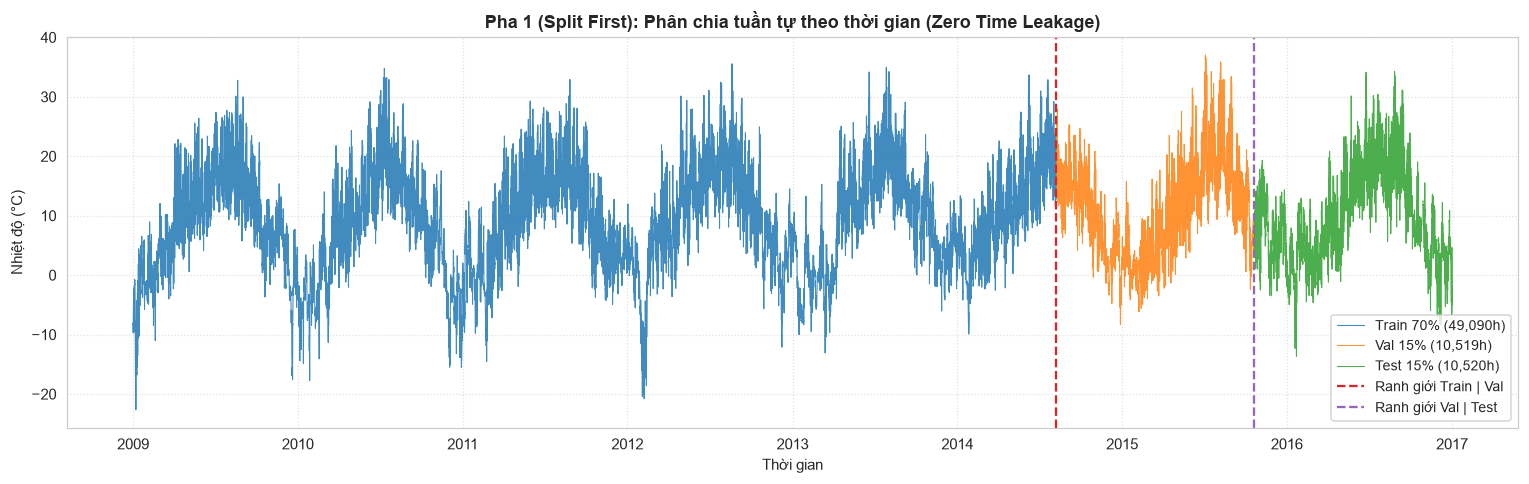

In [3]:
hourly_df = dm.load_and_resample()
train_df, val_df, test_df = dm.split_data(hourly_df)

print(f"Tổng sau Resample 1h: {len(hourly_df):,} giờ")
print(f"  - Train (70%): {len(train_df):,}h ({train_df.index.min()} -> {train_df.index.max()})")
print(f"  - Val   (15%): {len(val_df):,}h ({val_df.index.min()} -> {val_df.index.max()})")
print(f"  - Test  (15%): {len(test_df):,}h ({test_df.index.min()} -> {test_df.index.max()})")

plot_data_split_timeline(train_df, val_df, test_df)

**Biểu đồ 2 — Pha 1: Split First (`Line Timeline`):**
- **Là gì & Tại sao chọn Line Timeline:** Biểu diễn 3 phân tập **Train (70%)**, **Val (15%)**, **Test (15%)** nối tiếp nhau theo chiều thời gian, tách bạch bởi 2 đường ranh giới.
- **Ý nghĩa chống rò rỉ:** Chuỗi thời gian không được chia ngẫu nhiên (`shuffle=True`); chia tuần tự đảm bảo $\max(\text{Train}) < \min(\text{Val}) < \min(\text{Test})$. Từ đây khóa kín `Val` và `Test`.

---
## Phần 3: Pha 2 — Khám Phá Dữ Liệu Chỉ Trên Tập Train (6 Biểu Đồ Cốt Lõi)

In [4]:
display(train_df.describe().T[["mean", "std", "min", "50%", "max"]].round(2))
for k, v in summarize_eda_insights(train_df).items():
    print(f"  * {k}: {v}")

,mean,std,min,50%,max
p (mbar),988.66,8.29,934.91,989.11,1012.78
T (degC),9.11,8.65,-22.65,9.20,35.52
Tpot (K),283.20,8.71,250.97,283.32,309.72
Tdew (degC),4.61,6.97,-24.60,4.97,23.02
rh (%),75.94,16.46,13.68,79.17,100.00
VPmax (mbar),13.35,7.68,0.98,11.65,57.94
VPact (mbar),9.36,4.21,0.82,8.71,28.17
VPdef (mbar),3.99,4.79,0.00,2.16,41.82
sh (g/kg),5.92,2.67,0.52,5.50,18.03
H2OC (mmol/mol),9.47,4.26,0.83,8.82,28.66


  * n_rows_train: 49090
  * missing_total: 0
  * temp_mean_degC: 9.11
  * temp_median_degC: 9.2
  * temp_std_degC: 8.65
  * temp_min_degC: -22.65
  * temp_max_degC: 35.52
  * temp_skew: -0.095
  * warmest_hour: 15h (12.44°C)
  * coldest_hour: 5h (5.99°C)
  * top_positive_corr: {'Tpot (K)': 0.997, 'VPmax (mbar)': 0.95, 'Tdew (degC)': 0.902}
  * top_negative_corr: {'p (mbar)': -0.028, 'rh (%)': -0.563, 'rho (g/m**3)': -0.965}
  * autocorrelation: {'lag_24h': 0.9222, 'lag_48h': 0.8672, 'lag_72h': 0.8309, 'lag_168h': 0.7721}


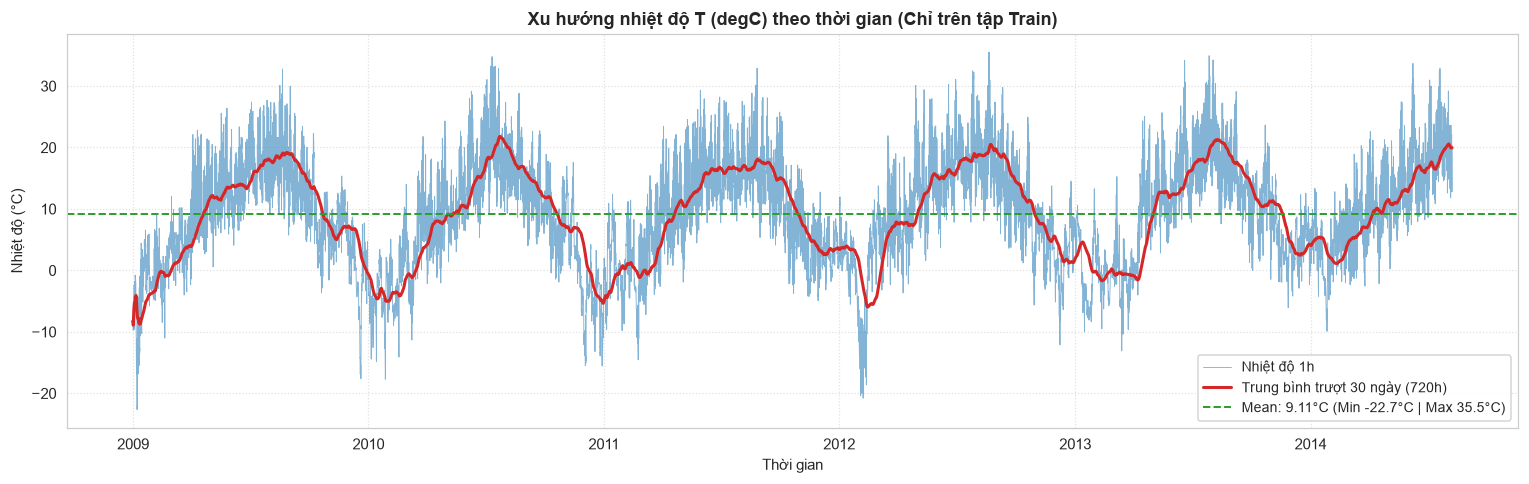

In [5]:
# Biểu đồ 3: Xu hướng nhiệt độ dài hạn + trung bình trượt 30 ngày
plot_temperature_trend(train_df)

**Biểu đồ 3 — Xu hướng nhiệt độ dài hạn (`Line + Rolling Mean 30 ngày`):**
- **Là gì & Tại sao chọn:** Đường xanh là nhiệt độ 1h, đường đỏ là trung bình trượt 30 ngày (`rolling(720)` = 30×24h) giúp lọc nhiễu ngày-đêm để nhìn rõ chu kỳ năm.
- **Ý nghĩa cho mô hình:** Nhiệt độ dao động mạnh theo mùa (`-22.65°C` đến `+35.52°C`, Mean `9.11°C`) $\Rightarrow$ chuỗi có tính mùa vụ mạnh, cần đầu vào **168h (7 ngày)** để nắm bắt nền nhiệt mùa hiện tại.

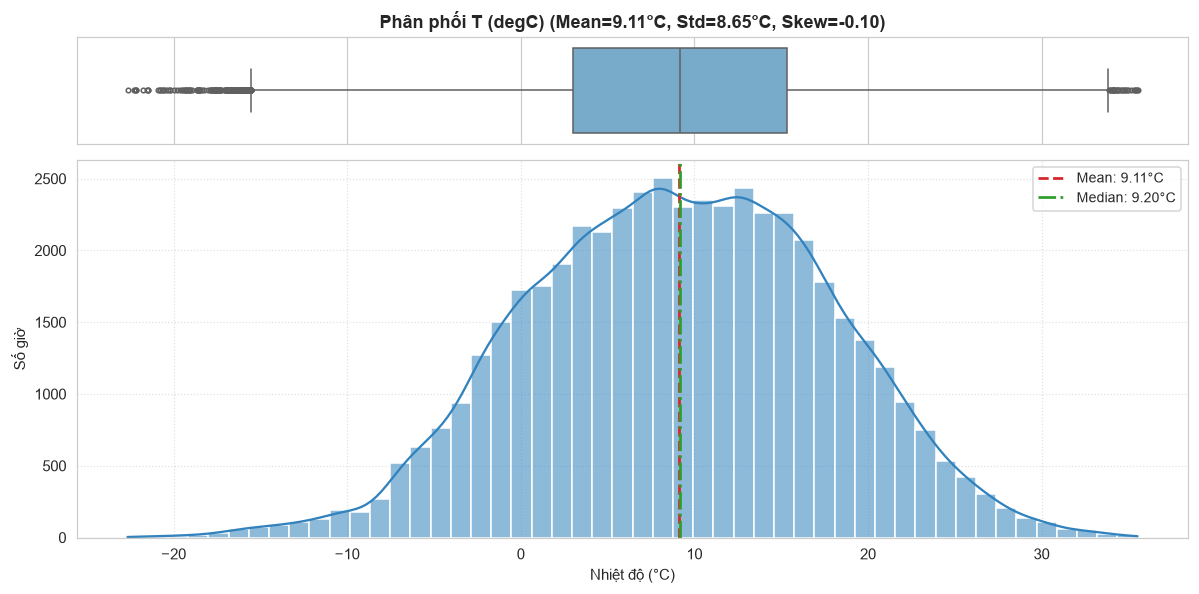

In [6]:
# Biểu đồ 4: Phân phối nhiệt độ T (degC)
plot_temperature_distribution(train_df)

**Biểu đồ 4 — Phân phối nhiệt độ `T (degC)` (`Boxplot + Histogram/KDE`):**
- **Là gì & Tại sao chọn:** Kết hợp Histogram/KDE xem hình dạng phân phối và Boxplot phát hiện ngoại lai (outliers).
- **Ý nghĩa cho mô hình:** Phân phối trải rộng (`Std = 8.65°C`), gần đối xứng (`Mean = 9.11°C ≈ Median = 9.20°C`, `Skew = -0.095`), có đuôi rét đậm mùa đông `< -15°C` $\Rightarrow$ dùng ngưỡng đánh giá $\pm 1.5^\circ\text{C}$ cùng `MAE`/`RMSE` là rất chặt chẽ.

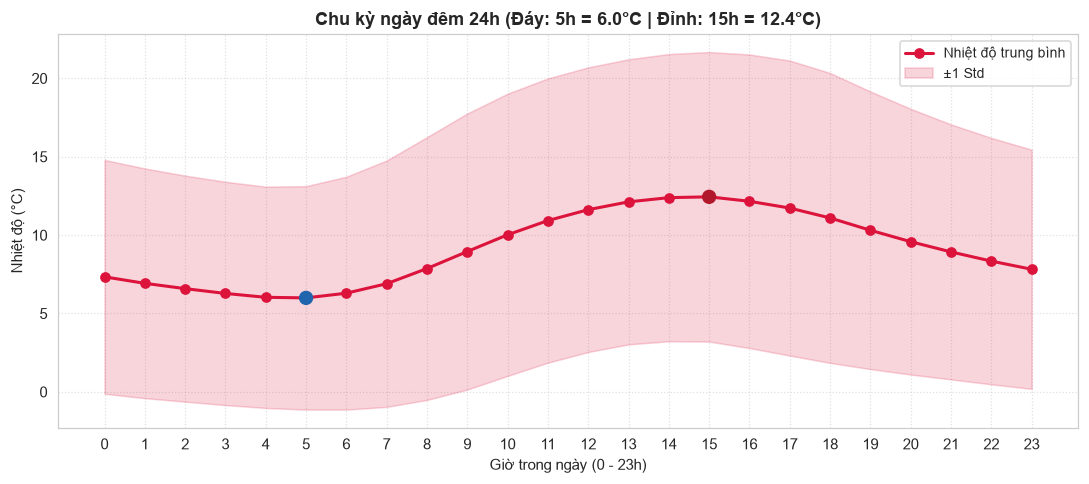

In [7]:
# Biểu đồ 5: Chu kỳ ngày đêm 24 giờ
plot_diurnal_cycle(train_df)

**Biểu đồ 5 — Chu kỳ ngày đêm 24 giờ (`Line Mean ± 1 Std`):**
- **Là gì & Tại sao chọn:** Gom nhóm theo từng giờ trong ngày (`0–23h`) để thấy quy luật nhiệt độ lên xuống theo chu kỳ mặt trời.
- **Ý nghĩa cho mô hình:** Đáy lúc **5h sáng (`5.99°C`)**, đỉnh lúc **15h chiều (`12.44°C`)**. Dự báo **72 giờ = đúng 3 chu kỳ ngày-đêm liên tiếp**, mô hình cần học tốt nhịp 24h này.

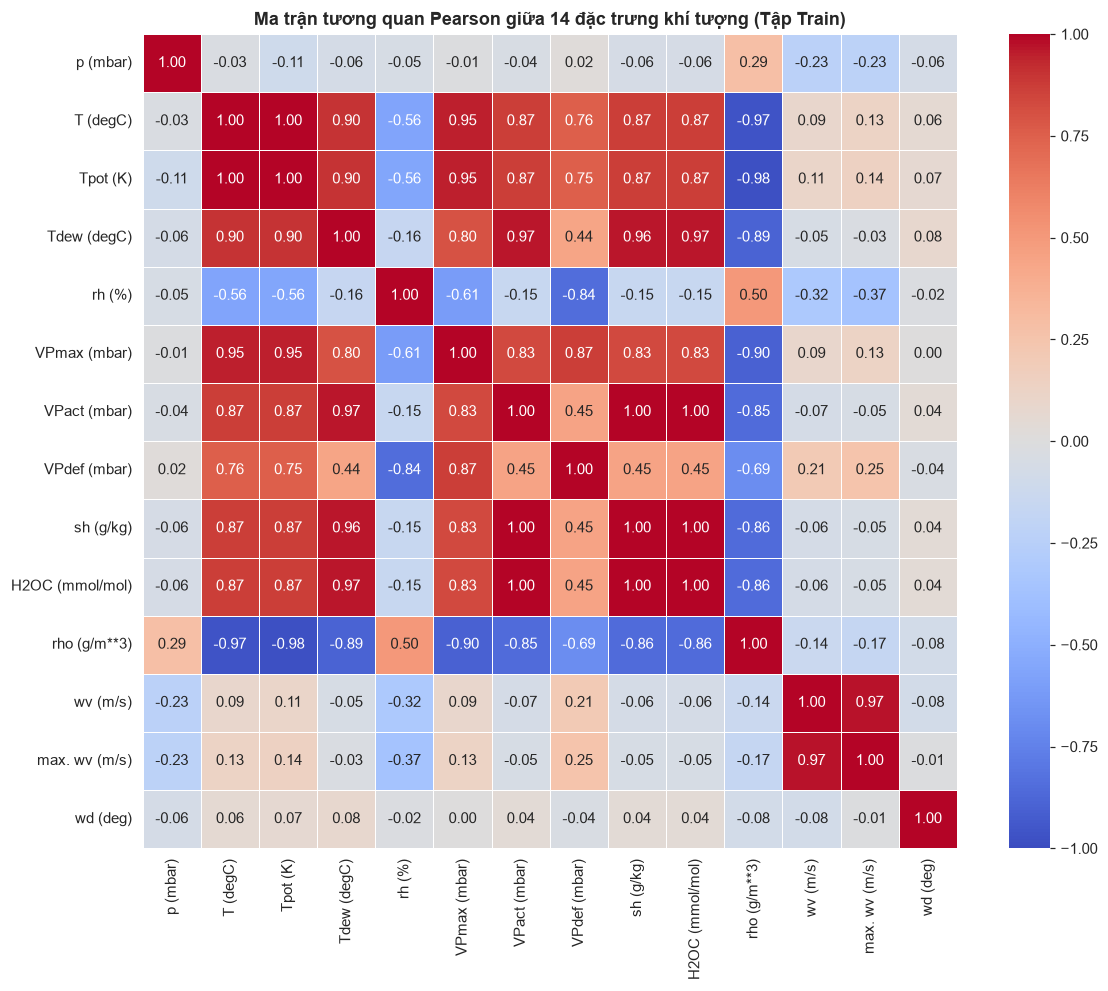

In [8]:
# Biểu đồ 6: Ma trận tương quan Pearson 14 đặc trưng khí tượng
plot_correlation_heatmap(train_df)

**Biểu đồ 6 — Ma trận tương quan Pearson 14×14 (`Heatmap`):**
- **Là gì & Tại sao chọn:** Tổng hợp nhanh toàn bộ quan hệ tuyến tính giữa 14 biến vào 1 bảng màu đối xứng `[-1, +1]`.
- **Ý nghĩa cho mô hình:** `T (degC)` tương quan thuận rất mạnh với `Tpot (+0.997)`, `VPmax (+0.950)`, `Tdew (+0.902)` và nghịch rất mạnh với `rho (-0.965)`, `rh (-0.563)`. Các biến gió/áp suất (`p`, `wv`, `wd`) tương quan tuyến tính yếu nhưng chứa tín hiệu phi tuyến báo trước đổi gió/mưa bão $\Rightarrow$ giữ đủ **14 biến**.

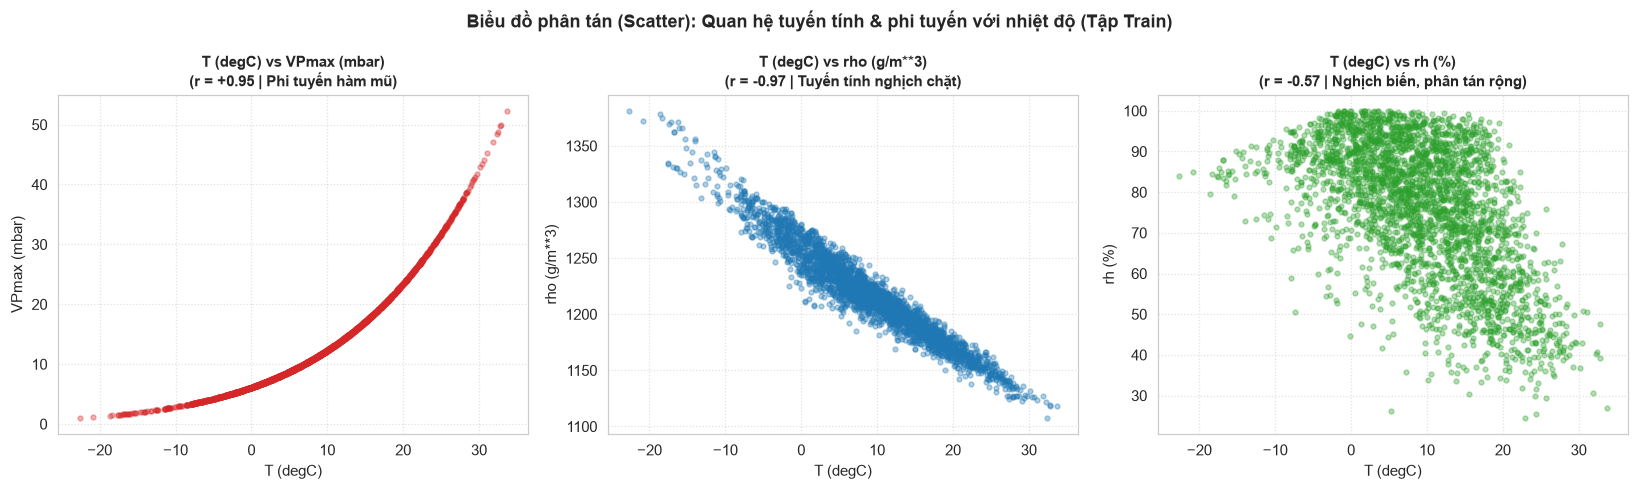

In [9]:
# Biểu đồ 7: Biểu đồ phân tán (Scatter) — Quan hệ tuyến tính & phi tuyến với T (degC)
plot_scatter_relationships(train_df)

**Biểu đồ 7 — Quan hệ phi tuyến & tuyến tính (`Scatter Plot`):**
- **Là gì & Tại sao chọn:** Heatmap chỉ đo tương quan tuyến tính, nên cần Scatter Plot để kiểm tra hình dạng thực tế của dữ liệu.
- **Ý nghĩa cho mô hình:** `T` vs `VPmax (mbar)` tạo **đường cong hàm mũ phi tuyến** (định luật Clausius–Clapeyron) $\Rightarrow$ bằng chứng trực quan chứng minh phải dùng **Deep Learning (LSTM / Attention / Transformer)** thay vì hồi quy tuyến tính.

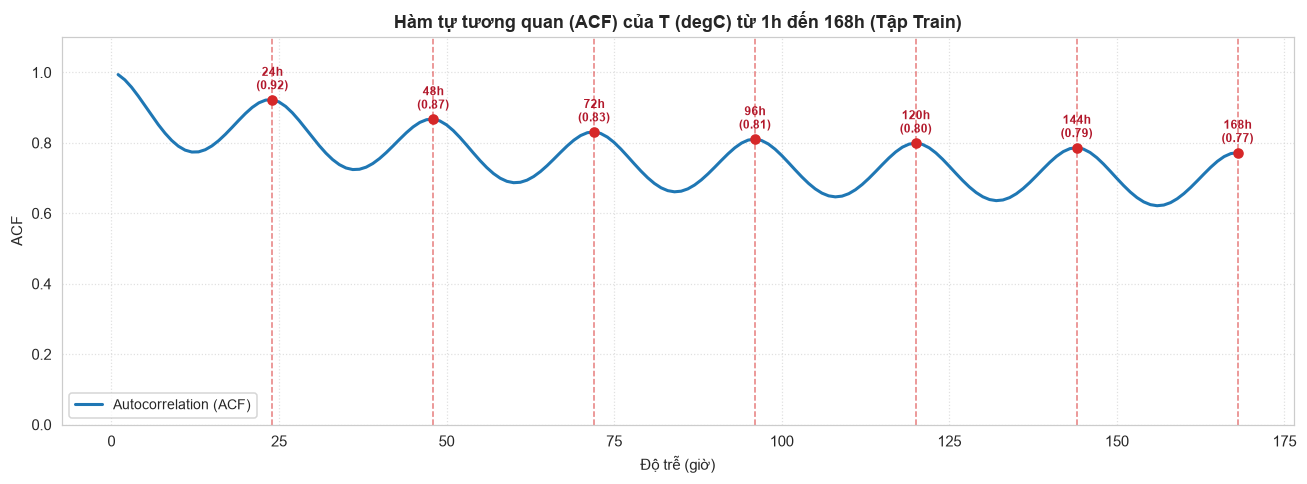

In [10]:
# Biểu đồ 8: Hàm tự tương quan ACF (1h -> 168h)
plot_autocorrelation(train_df, max_lag=168)

**Biểu đồ 8 — Hàm tự tương quan ACF 1h–168h (`Line ACF`):**
- **Là gì & Tại sao chọn:** Đo độ tương quan giữa nhiệt độ hiện tại $T(t)$ và quá khứ $T(t - k)$ từ $k=1$ đến $168$ giờ.
- **Ý nghĩa cho mô hình (điểm nhấn kiến trúc):** Các đỉnh lặp lại chính xác mỗi **24h** (`24h: 0.92`, `48h: 0.87`, `72h: 0.83`, ..., `168h: 0.77`) $\Rightarrow$ lý giải trực tiếp việc chọn **`168h -> 72h`** và giải thích vì sao **Bahdanau Attention / Transformer** vượt trội Baseline LSTM (có thể chú ý trực tiếp vào các mốc bội số 24h trong quá khứ).

---
## Phần 4: Pha 3 & Pha 4 — Chuẩn Hóa, Cửa Sổ Trượt & Kiểm Định Zero Leakage

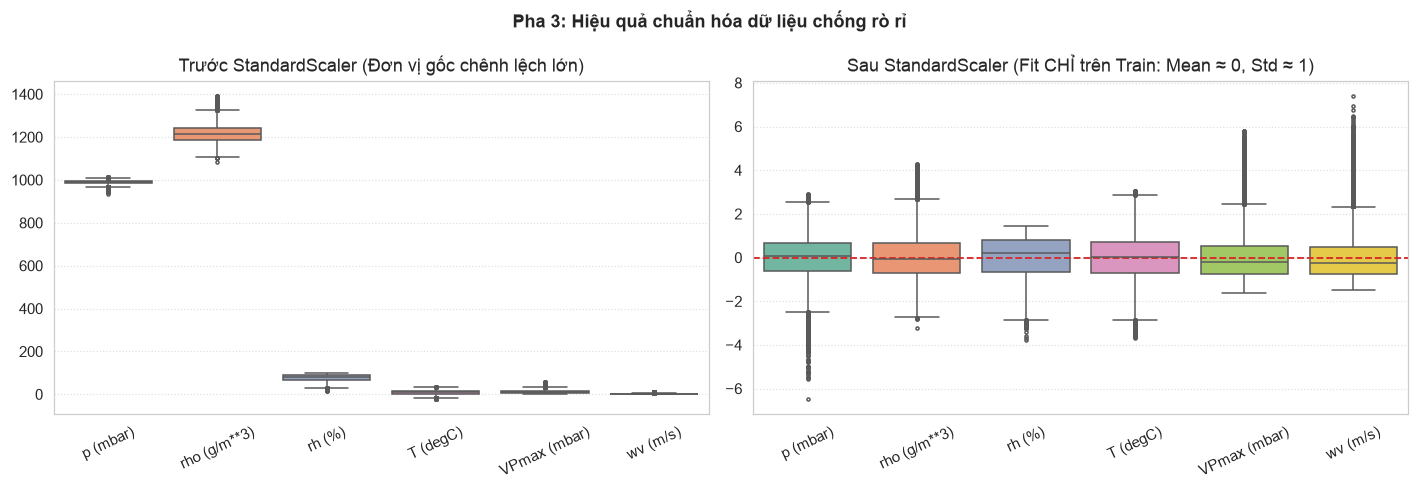

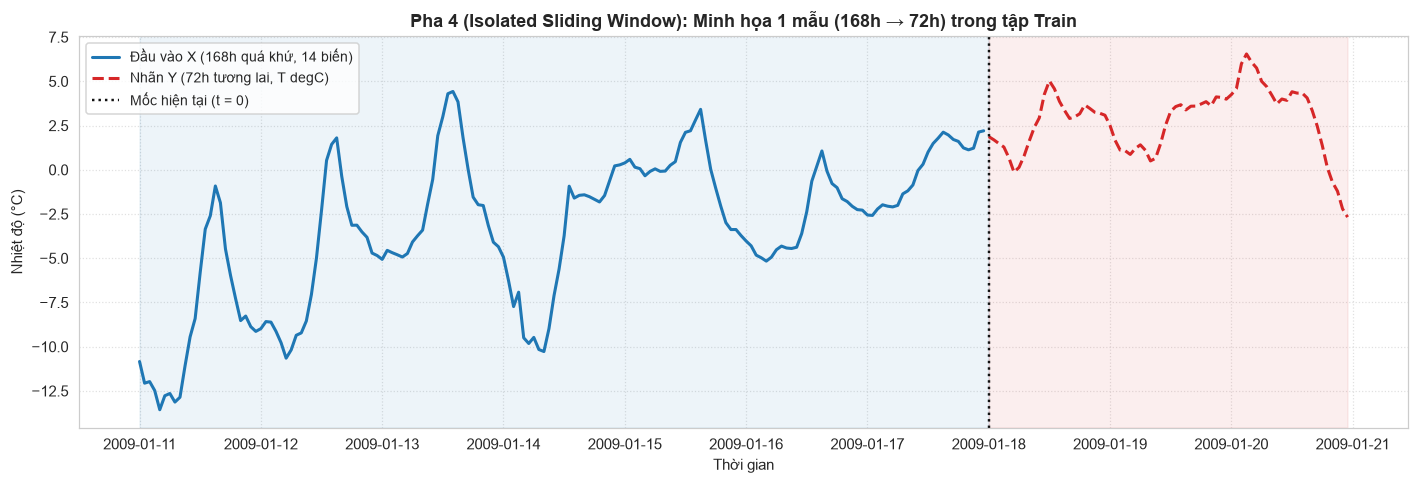

In [11]:
dm.setup()
train_scaled, _, _ = dm.fit_scaler_and_impute()

# Biểu đồ 9: Trước & Sau StandardScaler (fit chỉ trên Train)
plot_scaling_comparison(dm.train_df.ffill().bfill(), train_scaled, dm.features)

# Biểu đồ 10: Minh họa 1 mẫu Sliding Window (168h -> 72h) nội bộ Train
plot_sliding_window_example(dm.train_df.ffill().bfill(), seq_len=dm.seq_len, pred_len=dm.pred_len, start_idx=240)

In [12]:
# Kiểm định tự động Zero Data Leakage & Hợp đồng kích thước Tensor
assert dm.verify_zero_leakage() is True
train_loader, val_loader, test_loader = dm.get_dataloaders(batch_size=cfg["batch_size"], num_workers=0)
x_b, y_b = next(iter(train_loader))

print(f"[PASS] Zero Leakage: scaler.n_samples_seen_ ({int(dm.scaler.n_samples_seen_):,}) == len(train_df) ({len(dm.train_df):,})")
print(f"[PASS] Tensor Shape: X = {tuple(x_b.shape)}, Y = {tuple(y_b.shape)}")
print(f"[PASS] Sliding Windows: Train={len(dm.train_dataset):,} | Val={len(dm.val_dataset):,} | Test={len(dm.test_dataset):,}")

[PASS] Zero Leakage: scaler.n_samples_seen_ (49,090) == len(train_df) (49,090)
[PASS] Tensor Shape: X = (64, 168, 14), Y = (64, 72, 1)
[PASS] Sliding Windows: Train=48,851 | Val=10,280 | Test=10,281


**Biểu đồ 9 & 10 — Pha 3 (`StandardScaler`) & Pha 4 (`Sliding Window`):**
- **Biểu đồ 9 (`Boxplot` so sánh thang đo):** Trước chuẩn hóa `rho ~1200`, `p ~990` lớn gấp hàng trăm lần `wv ~2`; sau `StandardScaler` (chỉ `fit` trên Train), toàn bộ 14 biến về cùng thang `Mean ≈ 0, Std ≈ 1` giúp gradient ổn định.
- **Biểu đồ 10 (`Sliding Window`):** Minh họa 1 cặp mẫu `(168h quá khứ -> 72h tương lai)` cắt độc lập bên trong tập Train, không vắt ngang biên Train–Val–Test.

---
## Phần 5: Ghi Chú Feature Engineering (Chuẩn Bị Vấn Đáp)
- **Đã triển khai (5 bước tiền xử lý trong `src/data_module.py`):** Lọc lỗi `-9999.0` → Resample `1h` → Điền khuyết nội bộ `ffill/bfill` → `StandardScaler` fit trên Train → Sliding Window `(168×14 -> 72×1)`.
- **Hướng mở rộng (Future Work — giữ nguyên 14 biến gốc để đúng hợp đồng `input_dim=14` của toàn nhóm):** Biến đổi gió thành vector 2D ($W_x = wv\cos(\text{wd}),\; W_y = wv\sin(\text{wd})$) và mã hóa tuần hoàn thời gian (`Day/Year sin-cos`).